In [1]:
import xarray as xr
import glob
import pandas as pd
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from cartopy.io.shapereader import Reader as ShapeReader

In [2]:
def read_mar_var(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).isel(ATMLAY3_3=0, SECTOR=0, SECTOR1_1=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined


def read_mar_var_AP(path_pattern, var_names, months=[11, 12, 1, 2, 3], time_slice=('19800101', '20220331')):
    """
    Reads MAR NetCDF files, selects specified variables and dimensions,
    filters by months and time range.

    Parameters:
        path_pattern (str): File path pattern for NetCDF files.
        var_names (list): List of variable names to extract.
        months (list, optional): Months to filter. Default is summer in Patagonia.
        time_slice (tuple, optional): Start and end date for filtering. Default is ('19800101', '20220331').

    Returns:
        xarray.Dataset: Concatenated and filtered dataset.
    """
    files = sorted(glob.glob(path_pattern))
    ds_list = []

    for f in files:
        ds = xr.open_dataset(f).sel(X = slice(-2660, -2120), Y= slice(800, 1700)).isel(SECTOR=0, SECTOR1_1=0, ATMLAY=0)[var_names]
        ds = ds.sel(TIME=ds['TIME'].dt.month.isin(months))
        ds['TIME'] = ds['TIME'].dt.floor('D')
        ds_list.append(ds)

    ds_combined = xr.concat(ds_list, dim='TIME').sel(TIME=slice(*time_slice))
    return ds_combined

def compute_daily_anomalies(ds: xr.DataArray, time_dim: str = "time") -> xr.DataArray:
    """
    Compute daily anomalies of a temperature field based on day-of-year climatology.
    
    Parameters:
        ds (xr.DataArray): Input data with a time dimension (e.g., daily temperature).
        time_dim (str): Name of the time dimension (default is 'time').

    Returns:
        anomalies (xr.DataArray): Daily anomalies with same shape as input.
    """

    # Create dayofyear coordinate
    doy = ds[time_dim].dt.dayofyear
    ds = ds.assign_coords(dayofyear=(time_dim, doy.data))

    # Compute climatology (mean for each day of the year)
    climatology = ds.groupby("dayofyear").mean(time_dim)

    # Subtract climatology to get anomalies
    anomalies = ds.groupby("dayofyear") - climatology

    return anomalies


In [3]:
files = sorted(glob.glob('/home/cr2/cmtorres/MAR_DATA_SEL/Patagonia/*.nc'))
ds_MAR = xr.open_dataset(files[0])
LAT = ds_MAR['LAT']
LON = ds_MAR['LON']

files = sorted(glob.glob('/home/cr2/cmtorres/MAR_DATA_SEL/APeninsula/*.nc'))
ds_MAR_AP = xr.open_dataset(files[0]).sel(X = slice(-2660, -2120), Y= slice(800, 1700))
LAT_AP = ds_MAR_AP['LAT']
LON_AP = ds_MAR_AP['LON']

In [4]:
with open('/home/cr2/cmtorres/DATA/mask_PAT.npy', 'rb') as f:
    mask_PAT = np.load(f)

In [5]:
import cartopy.feature as cfeature
from shapely.geometry import Point
from shapely.prepared import prep

# --- Coastline polygons from Natural Earth (land) ---
land_feature = cfeature.NaturalEarthFeature("physical", "land", "10m")
land_geom = [prep(geom) for geom in land_feature.geometries()]

# --- Create coordinate grids ---
lon2d, lat2d = LON_AP, LAT_AP
mask_AP = np.zeros(lon2d.shape, dtype=bool)

# --- Build mask: True = continente
for i in range(lon2d.shape[0]):
    for j in range(lon2d.shape[1]):
        pt = Point(lon2d[i, j], lat2d[i, j])
        # True se está na terra
        if any(geom.contains(pt) for geom in land_geom):
            mask_AP[i, j] = True
        else:
            mask_AP[i, j] = False


# --- 🔧 Apply latitude limits (-68 ≤ lat ≤ -60)
#mask_AP[(lat2d < -68) | (lat2d > -60)] = False

In [12]:
def process_mar_patagonia(path_pattern, mask, spatial_dims=('Y25_370', 'X29_205')):
    """Procesa SEB para Patagonia usando SWU directo e incluye SWnet y LWnet."""
    ds_SWD = read_mar_var(path_pattern=path_pattern, var_names=['SWD']).where(mask)
    ds_SWU = read_mar_var(path_pattern=path_pattern, var_names=['SWU']).where(mask)
    ds_LWD = read_mar_var(path_pattern=path_pattern, var_names=['LWD']).where(mask)
    ds_LWU = read_mar_var(path_pattern=path_pattern, var_names=['LWU']).where(mask)
    ds_SHF = read_mar_var(path_pattern=path_pattern, var_names=['SHF']).where(mask)
    ds_LHF = read_mar_var(path_pattern=path_pattern, var_names=['LHF']).where(mask)

    # Componentes individuales
    swd = ds_SWD['SWD'].mean(spatial_dims).to_dataframe()['SWD']
    swu = (-1 * ds_SWU['SWU']).mean(spatial_dims).to_dataframe()['SWU']
    lwd = ds_LWD['LWD'].mean(spatial_dims).to_dataframe()['LWD']
    lwu = (-1 * ds_LWU['LWU']).mean(spatial_dims).to_dataframe()['LWU']
    shf = ds_SHF['SHF'].mean(spatial_dims).to_dataframe()['SHF']
    lhf = ds_LHF['LHF'].mean(spatial_dims).to_dataframe()['LHF']

    # Componentes NETOS
    swnet = (ds_SWD['SWD'] - ds_SWU['SWU']).mean(spatial_dims).to_dataframe(name='SWnet')['SWnet']
    lwnet = (ds_LWD['LWD'] - ds_LWU['LWU']).mean(spatial_dims).to_dataframe(name='LWnet')['LWnet']

    # Balance Neto Total (Qnet)
    qnet = (
        ds_SWD['SWD'] - ds_SWU['SWU'] + ds_LWD['LWD'] - ds_LWU['LWU'] + ds_SHF['SHF'] + ds_LHF['LHF']
    ).mean(spatial_dims).to_dataframe(name='Qnet')['Qnet']

    return pd.concat(
        [
            swd.rename("SWD"),
            swu.rename("SWU"),
            lwd.rename("LWD"),
            lwu.rename("LWU"),
            swnet.rename("SWnet"),
            lwnet.rename("LWnet"),
            shf.rename("SHF"),
            lhf.rename("LHF"),
            qnet,
        ],
        axis=1,
    )


def process_mar_apis(path_pattern, mask, spatial_dims=('Y', 'X')):
    """Procesa SEB para Península Antártica usando Albedo e incluye SWnet y LWnet."""
    ds_SWD = read_mar_var_AP(path_pattern=path_pattern, var_names=['SWD']).where(mask)
    ds_ALB = read_mar_var_AP(path_pattern=path_pattern, var_names=['AL']).where(mask)
    ds_LWD = read_mar_var_AP(path_pattern=path_pattern, var_names=['LWD']).where(mask)
    ds_LWU = read_mar_var_AP(path_pattern=path_pattern, var_names=['LWU']).where(mask)
    ds_SHF = read_mar_var_AP(path_pattern=path_pattern, var_names=['SHF']).where(mask)
    ds_LHF = read_mar_var_AP(path_pattern=path_pattern, var_names=['LHF']).where(mask)

    swd_da = ds_SWD['SWD']
    swu_da = -1 * (ds_SWD['SWD'] * ds_ALB['AL'])

    # Componentes individuales
    swd = swd_da.mean(spatial_dims).to_dataframe(name='SWD')['SWD']
    swu = swu_da.mean(spatial_dims).to_dataframe(name='SWU')['SWU']
    lwd = ds_LWD['LWD'].mean(spatial_dims).to_dataframe()['LWD']
    lwu = (-1 * ds_LWU['LWU']).mean(spatial_dims).to_dataframe()['LWU']
    shf = ds_SHF['SHF'].mean(spatial_dims).to_dataframe()['SHF']
    lhf = ds_LHF['LHF'].mean(spatial_dims).to_dataframe()['LHF']

    # Componentes NETOS (SWnet considerando albedo)
    swnet = (ds_SWD['SWD'] * (1 - ds_ALB['AL'])).mean(spatial_dims).to_dataframe(name='SWnet')['SWnet']
    lwnet = (ds_LWD['LWD'] - ds_LWU['LWU']).mean(spatial_dims).to_dataframe(name='LWnet')['LWnet']

    # Balance Neto Total (Qnet)
    qnet = (
        ds_SWD['SWD'] * (1 - ds_ALB['AL']) + ds_LWD['LWD'] - ds_LWU['LWU'] + ds_SHF['SHF'] + ds_LHF['LHF']
    ).mean(spatial_dims).to_dataframe(name='Qnet')['Qnet']

    return pd.concat(
        [
            swd.rename("SWD"),
            swu.rename("SWU"),
            lwd.rename("LWD"),
            lwu.rename("LWU"),
            swnet.rename("SWnet"),
            lwnet.rename("LWnet"),
            shf.rename("SHF"),
            lhf.rename("LHF"),
            qnet,
        ],
        axis=1,
    )

In [13]:
# =============================================================================
# 2. CARGA DE DATOS
# =============================================================================
path_patagonia = '/home/cr2/cmtorres/MAR_DATA_SEL/Patagonia/*.nc'
path_peninsula = '/home/cr2/cmtorres/MAR_DATA_SEL/APeninsula/*.nc'

# Ejecución de funciones
df_PIs = process_mar_patagonia(path_patagonia, mask_PAT, spatial_dims=('Y25_370', 'X29_205'))
df_APIS = process_mar_apis(path_peninsula, mask_AP, spatial_dims=('Y', 'X'))

df_patagonia = df_PIs
df_peninsula = df_APIS

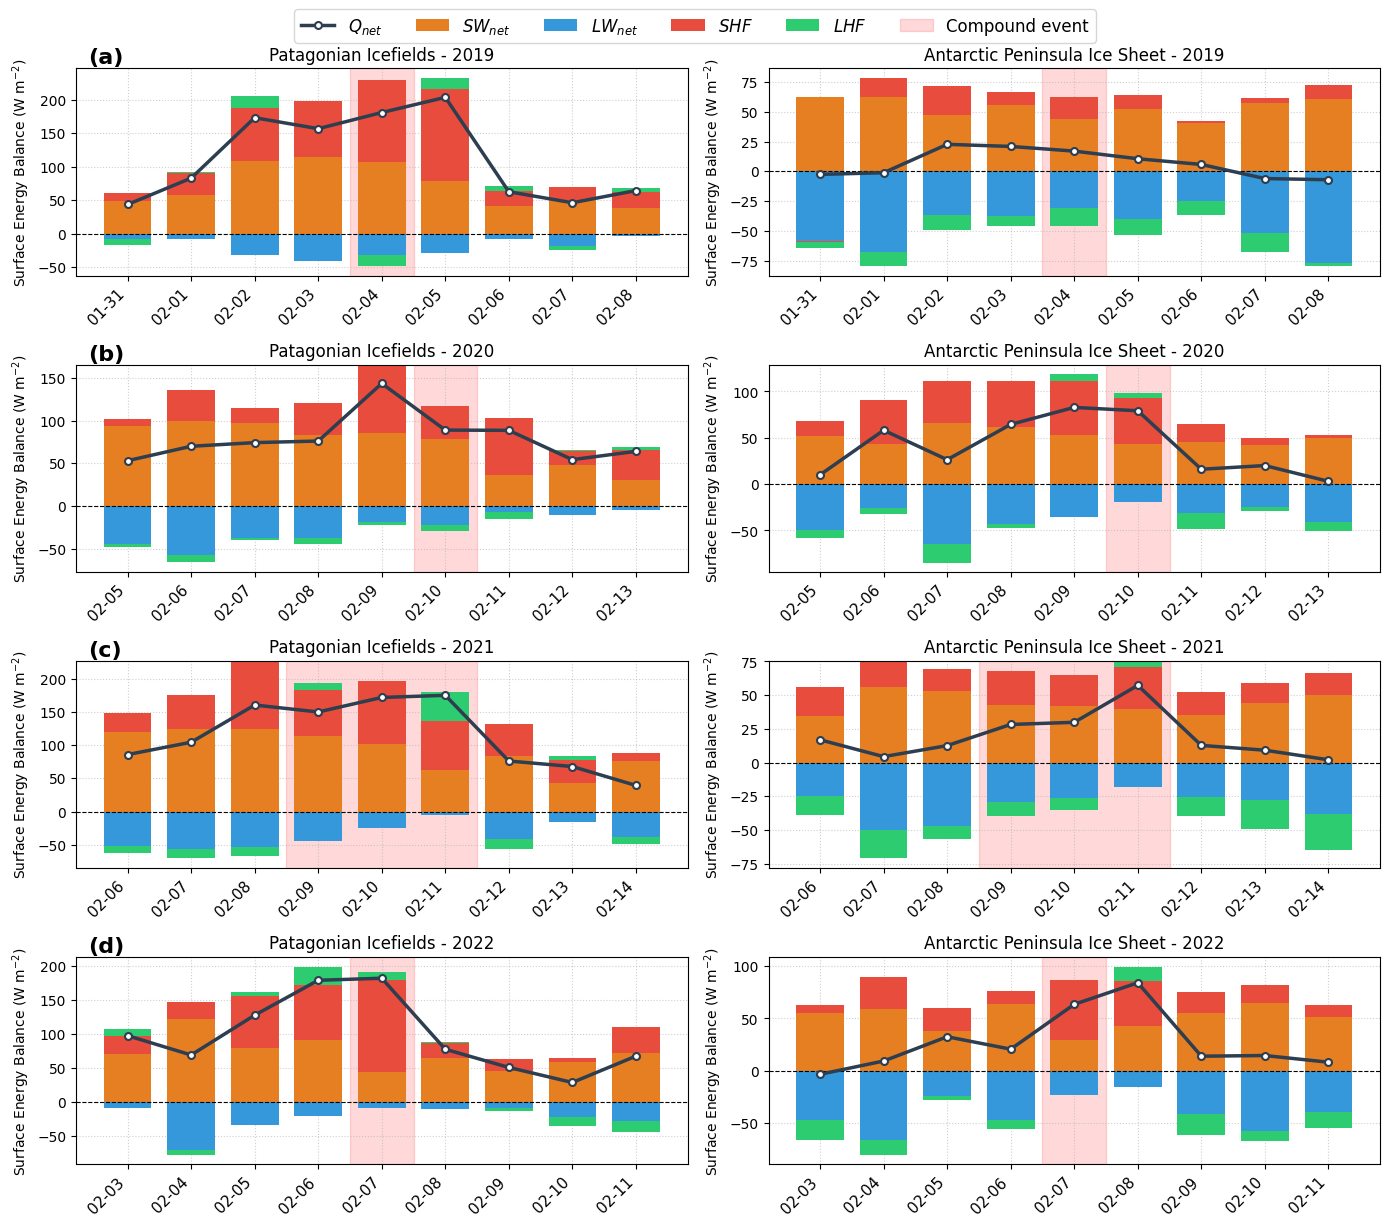

In [16]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_patagonia = df_PIs
df_peninsula = df_APIS

# Componentes netas para las barras
components = ["SWnet", "LWnet", "SHF", "LHF"]

# Paleta de colores para los componentes netos
colors_dict = {
    "SWnet": "#e67e22",  # Naranja
    "LWnet": "#3498db",  # Azul
    "SHF": "#e74c3c",    # Rojo
    "LHF": "#2ecc71",    # Verde
    "Qnet": "#2c3e50",   # Azul oscuro / Negro
}

# Formato de etiquetas LaTeX
labels_dict = {
    "SWnet": r"$SW_{net}$",
    "LWnet": r"$LW_{net}$",
    "SHF": r"$SHF$",
    "LHF": r"$LHF$",
    "Qnet": r"$Q_{net}$",
}

# Configuración de rangos de fechas
date_ranges = [
    {
        "start": np.datetime64("2019-01-31"),
        "end": np.datetime64("2019-02-08"),
        "event_start": np.datetime64("2019-02-04"),
        "event_end": np.datetime64("2019-02-04"),
        "label": "2019",
    },
    {
        "start": np.datetime64("2020-02-05"),
        "end": np.datetime64("2020-02-13"),
        "event_start": np.datetime64("2020-02-10"),
        "event_end": np.datetime64("2020-02-10"),
        "label": "2020",
    },
    {
        "start": np.datetime64("2021-02-06"),
        "end": np.datetime64("2021-02-14"),
        "event_start": np.datetime64("2021-02-09"),
        "event_end": np.datetime64("2021-02-11"),
        "label": "2021",
    },
    {
        "start": np.datetime64("2022-02-03"),
        "end": np.datetime64("2022-02-11"),
        "event_start": np.datetime64("2022-02-07"),
        "event_end": np.datetime64("2022-02-07"),
        "label": "2022",
    },
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 12), sharey=False)
year_labels = ["(a)", "(b)", "(c)", "(d)"]

def plot_stacked_seb(ax, df_slice):
    x = np.arange(len(df_slice))
    width = 0.75

    bottom_pos = np.zeros(len(df_slice))
    bottom_neg = np.zeros(len(df_slice))

    # Barras apiladas para cada componente NETO
    for comp in components:
        if comp in df_slice.columns:
            values = df_slice[comp].values
            pos_vals = np.where(values > 0, values, 0)
            neg_vals = np.where(values < 0, values, 0)

            label_text = labels_dict.get(comp, comp)

            if np.any(pos_vals > 0):
                ax.bar(
                    x,
                    pos_vals,
                    width=width,
                    bottom=bottom_pos,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_pos += pos_vals

            if np.any(neg_vals < 0):
                ax.bar(
                    x,
                    neg_vals,
                    width=width,
                    bottom=bottom_neg,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_neg += neg_vals

    # Línea con puntos destacada para Qnet
    if "Qnet" in df_slice.columns:
        ax.plot(
            x,
            df_slice["Qnet"],
            color=colors_dict.get("Qnet", "black"),
            linewidth=2.5,
            marker="o",
            markersize=5,
            mfc="white",
            mew=1.5,
            label=labels_dict["Qnet"],
            zorder=4,
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(df_slice.index.strftime("%m-%d"), rotation=45, ha="right", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6, zorder=1)


for i, rng in enumerate(date_ranges):
    start, end = rng["start"], rng["end"]
    event_start, event_end = rng["event_start"], rng["event_end"]

    # Filtrar datos por rango de fechas
    pat_slice = df_patagonia.loc[start:end]
    pen_slice = df_peninsula.loc[start:end]

    # Panel Izquierdo: Patagonia
    plot_stacked_seb(axes[i, 0], pat_slice)
    axes[i, 0].set_title(f"Patagonian Icefields - {rng['label']}")
    axes[i, 0].set_ylabel("Surface Energy Balance (W m$^{-2}$)")

    # Panel Derecho: Península Antártica
    plot_stacked_seb(axes[i, 1], pen_slice)
    axes[i, 1].set_title(f"Antarctic Peninsula Ice Sheet - {rng['label']}")
    axes[i, 1].set_ylabel("Surface Energy Balance (W m$^{-2}$)")

    # Sombreado vertical del evento
    time_index = pat_slice.index
    start_idx = np.where(time_index == event_start)[0][0]
    end_idx = np.where(time_index == event_end)[0][0]

    vspan_handle = axes[i, 0].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)
    axes[i, 1].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)

    # Etiqueta del subpanel (a, b, c, d)
    axes[i, 0].text(
        0.02,
        1.10,
        year_labels[i],
        transform=axes[i, 0].transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
    )

# Extracción de handles para la leyenda unificada
handles_dict = {}
for ax in axes.flat:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in handles_dict:
            handles_dict[label] = handle

handles_dict["Compound event"] = vspan_handle

# Leyenda global
fig.legend(
    handles_dict.values(),
    handles_dict.keys(),
    loc="upper center",
    ncol=len(handles_dict),
    bbox_to_anchor=(0.5, 1.025),
    frameon=True,
    fontsize=12,
)

plt.tight_layout()

# Guardar figura
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "SEB_cases_net.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()
#plt.close(fig)

In [20]:
def process_mar_patagonia(path_pattern, mask, spatial_dims=('Y25_370', 'X29_205')):
    """Procesa las componentes del SMB para Patagonia agrupando SF y RF en Precipitación (PR)."""
    ds_SF = read_mar_var(path_pattern=path_pattern, var_names=['SF']).where(mask)
    ds_RF = read_mar_var(path_pattern=path_pattern, var_names=['RF']).where(mask)
    ds_SU = read_mar_var(path_pattern=path_pattern, var_names=['SU']).where(mask)
    ds_RU = read_mar_var(path_pattern=path_pattern, var_names=['RU']).where(mask)

    # Precipitación total PR = SF + RF (Entrada de masa positiva)
    pr = (ds_SF['SF'] + ds_RF['RF']).mean(spatial_dims).to_dataframe(name='PR')['PR']

    # Salidas de masa (se consideran negativas)
    su = (-1 * ds_SU['SU']).mean(spatial_dims).to_dataframe()['SU']
    ru = (-1 * ds_RU['RU']).mean(spatial_dims).to_dataframe()['RU']

    # Balance de Masa Superficial Neto (SMB = PR - SU - RU)
    smb = (
        ds_SF['SF'] + ds_RF['RF'] - ds_SU['SU'] - ds_RU['RU']
    ).mean(spatial_dims).to_dataframe(name='SMB')['SMB']

    return pd.concat(
        [
            pr.rename("PR"),
            su.rename("SU"),
            ru.rename("RU"),
            smb,
        ],
        axis=1,
    )


def process_mar_apis(path_pattern, mask, spatial_dims=('Y', 'X')):
    """Procesa las componentes del SMB para la Península Antártica agrupando SF y RF en Precipitación (PR)."""
    ds_SF = read_mar_var_AP(path_pattern=path_pattern, var_names=['SF']).where(mask)
    ds_RF = read_mar_var_AP(path_pattern=path_pattern, var_names=['RF']).where(mask)
    ds_SU = read_mar_var_AP(path_pattern=path_pattern, var_names=['SU']).where(mask)
    ds_RU = read_mar_var_AP(path_pattern=path_pattern, var_names=['RU']).where(mask)

    # Precipitación total PR = SF + RF (Entrada de masa positiva)
    pr = (ds_SF['SF'] + ds_RF['RF']).mean(spatial_dims).to_dataframe(name='PR')['PR']

    # Salidas de masa (se consideran negativas)
    su = (-1 * ds_SU['SU']).mean(spatial_dims).to_dataframe()['SU']
    ru = (-1 * ds_RU['RU']).mean(spatial_dims).to_dataframe()['RU']

    # Balance de Masa Superficial Neto (SMB = PR - SU - RU)
    smb = (
        ds_SF['SF'] + ds_RF['RF'] - ds_SU['SU'] - ds_RU['RU']
    ).mean(spatial_dims).to_dataframe(name='SMB')['SMB']

    return pd.concat(
        [
            pr.rename("PR"),
            su.rename("SU"),
            ru.rename("RU"),
            smb,
        ],
        axis=1,
    )

In [21]:
# =============================================================================
# 2. CARGA DE DATOS
# =============================================================================
path_patagonia = '/home/cr2/cmtorres/MAR_DATA_SEL/Patagonia/*.nc'
path_peninsula = '/home/cr2/cmtorres/MAR_DATA_SEL/APeninsula/*.nc'

# Ejecución de funciones
df_PIs = process_mar_patagonia(path_patagonia, mask_PAT, spatial_dims=('Y25_370', 'X29_205'))
df_APIS = process_mar_apis(path_peninsula, mask_AP, spatial_dims=('Y', 'X'))

df_patagonia = df_PIs
df_peninsula = df_APIS

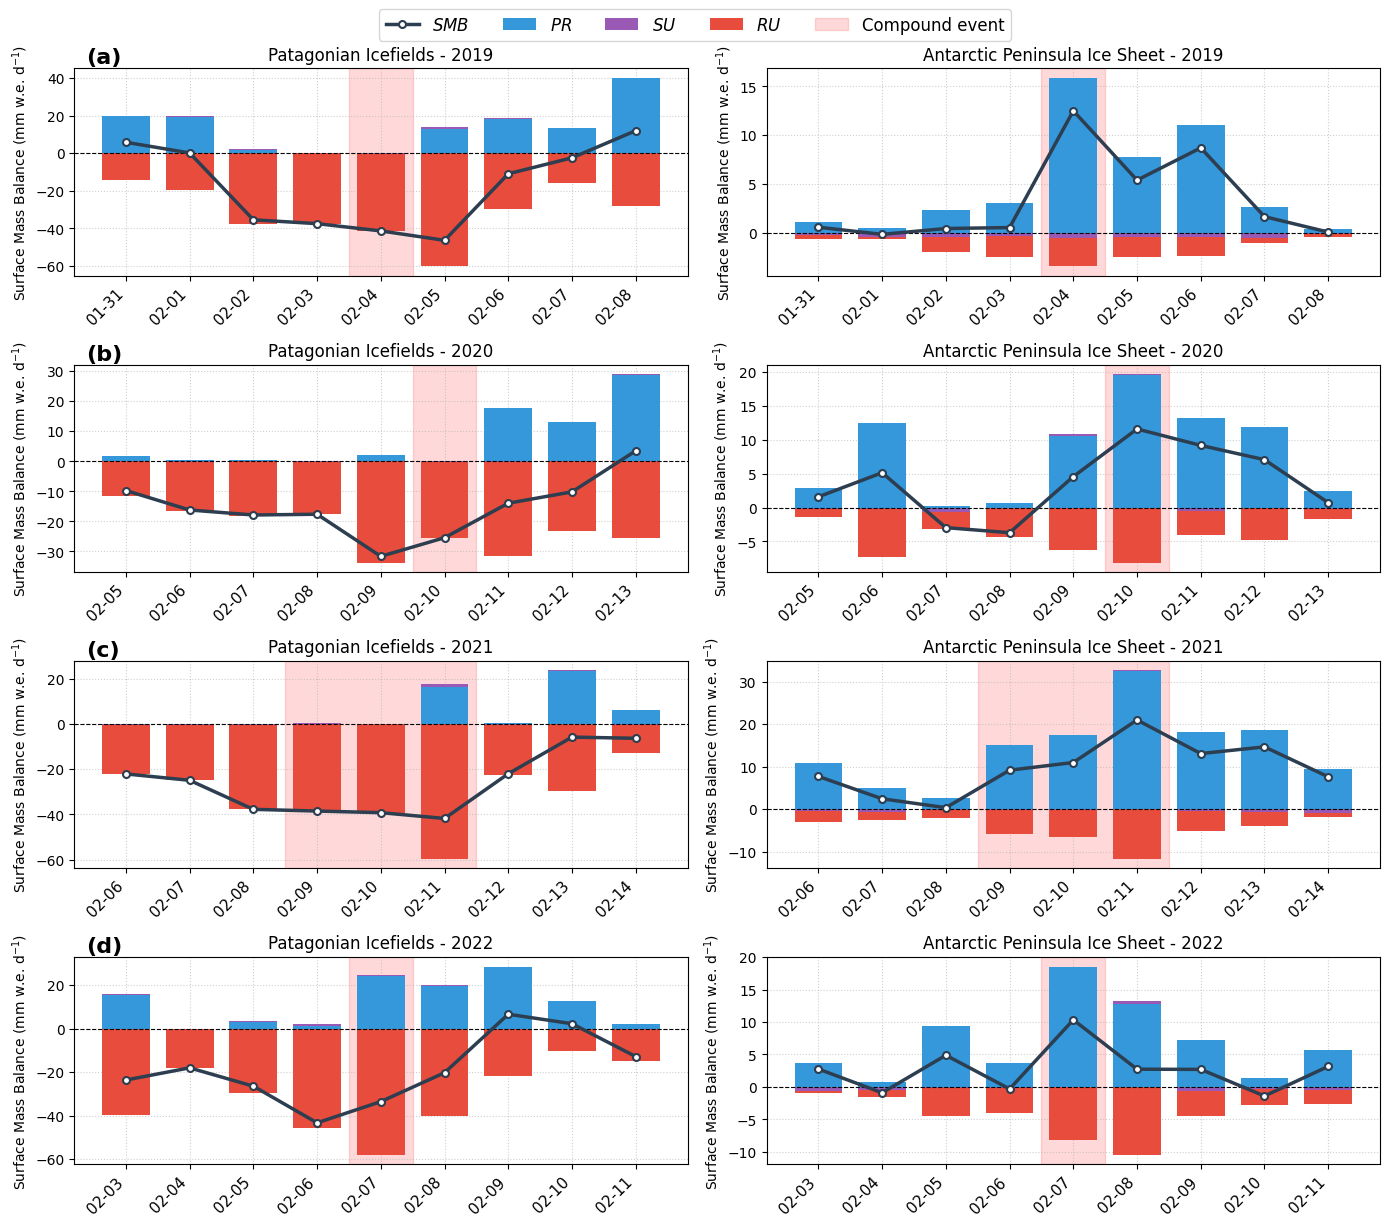

In [22]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_patagonia = df_PIs
df_peninsula = df_APIS

# Componentes del SMB para las barras (Precipitación total PR)
components = ["PR", "SU", "RU"]

# Paleta de colores para las componentes del SMB
colors_dict = {
    "PR": "#3498db",   # Azul (Precipitación Total)
    "SU": "#9b59b6",   # Púrpura (Sublimación/Evaporación)
    "RU": "#e74c3c",   # Rojo (Escurrimiento/Runoff)
    "SMB": "#2c3e50",  # Azul oscuro / Negro (SMB Neto)
}

# Formato de etiquetas LaTeX
labels_dict = {
    "PR": r"$PR$",
    "SU": r"$SU$",
    "RU": r"$RU$",
    "SMB": r"$SMB$",
}

# Configuración de rangos de fechas
date_ranges = [
    {
        "start": np.datetime64("2019-01-31"),
        "end": np.datetime64("2019-02-08"),
        "event_start": np.datetime64("2019-02-04"),
        "event_end": np.datetime64("2019-02-04"),
        "label": "2019",
    },
    {
        "start": np.datetime64("2020-02-05"),
        "end": np.datetime64("2020-02-13"),
        "event_start": np.datetime64("2020-02-10"),
        "event_end": np.datetime64("2020-02-10"),
        "label": "2020",
    },
    {
        "start": np.datetime64("2021-02-06"),
        "end": np.datetime64("2021-02-14"),
        "event_start": np.datetime64("2021-02-09"),
        "event_end": np.datetime64("2021-02-11"),
        "label": "2021",
    },
    {
        "start": np.datetime64("2022-02-03"),
        "end": np.datetime64("2022-02-11"),
        "event_start": np.datetime64("2022-02-07"),
        "event_end": np.datetime64("2022-02-07"),
        "label": "2022",
    },
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 12), sharey=False)
year_labels = ["(a)", "(b)", "(c)", "(d)"]

def plot_stacked_smb(ax, df_slice):
    x = np.arange(len(df_slice))
    width = 0.75

    bottom_pos = np.zeros(len(df_slice))
    bottom_neg = np.zeros(len(df_slice))

    # Barras apiladas para componentes de masa
    for comp in components:
        if comp in df_slice.columns:
            values = df_slice[comp].values
            pos_vals = np.where(values > 0, values, 0)
            neg_vals = np.where(values < 0, values, 0)

            label_text = labels_dict.get(comp, comp)

            if np.any(pos_vals > 0):
                ax.bar(
                    x,
                    pos_vals,
                    width=width,
                    bottom=bottom_pos,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_pos += pos_vals

            if np.any(neg_vals < 0):
                ax.bar(
                    x,
                    neg_vals,
                    width=width,
                    bottom=bottom_neg,
                    color=colors_dict.get(comp, "gray"),
                    label=label_text,
                    zorder=2,
                )
                bottom_neg += neg_vals

    # Línea destacada para SMB Neto
    if "SMB" in df_slice.columns:
        ax.plot(
            x,
            df_slice["SMB"],
            color=colors_dict.get("SMB", "black"),
            linewidth=2.5,
            marker="o",
            markersize=5,
            mfc="white",
            mew=1.5,
            label=labels_dict["SMB"],
            zorder=4,
        )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(df_slice.index.strftime("%m-%d"), rotation=45, ha="right", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6, zorder=1)


for i, rng in enumerate(date_ranges):
    start, end = rng["start"], rng["end"]
    event_start, event_end = rng["event_start"], rng["event_end"]

    # Filtrar datos por rango de fechas (usando .copy() para evitar advertencias)
    pat_slice = df_patagonia.loc[start:end].copy()
    pen_slice = df_peninsula.loc[start:end].copy()

    # Asegurar la existencia de PR
    for df_s in [pat_slice, pen_slice]:
        if "PR" not in df_s.columns:
            if "PRECP" in df_s.columns:
                df_s["PR"] = df_s["PRECP"]
            elif "SF" in df_s.columns and "RF" in df_s.columns:
                df_s["PR"] = df_s["SF"] + df_s["RF"]

    # Panel Izquierdo: Patagonia
    plot_stacked_smb(axes[i, 0], pat_slice)
    axes[i, 0].set_title(f"Patagonian Icefields - {rng['label']}")
    axes[i, 0].set_ylabel("Surface Mass Balance (mm w.e. d$^{-1}$)")

    # Panel Derecho: Península Antártica
    plot_stacked_smb(axes[i, 1], pen_slice)
    axes[i, 1].set_title(f"Antarctic Peninsula Ice Sheet - {rng['label']}")
    axes[i, 1].set_ylabel("Surface Mass Balance (mm w.e. d$^{-1}$)")

    # Sombreado vertical del evento
    time_index = pat_slice.index
    start_idx = np.where(time_index == event_start)[0][0]
    end_idx = np.where(time_index == event_end)[0][0]

    vspan_handle = axes[i, 0].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)
    axes[i, 1].axvspan(start_idx - 0.5, end_idx + 0.5, color="red", alpha=0.15, zorder=0)

    # Etiqueta del subpanel (a, b, c, d)
    axes[i, 0].text(
        0.02,
        1.10,
        year_labels[i],
        transform=axes[i, 0].transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
    )

# Extracción de handles para la leyenda unificada
handles_dict = {}
for ax in axes.flat:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in handles_dict:
            handles_dict[label] = handle

handles_dict["Compound event"] = vspan_handle

# Leyenda global
fig.legend(
    handles_dict.values(),
    handles_dict.keys(),
    loc="upper center",
    ncol=len(handles_dict),
    bbox_to_anchor=(0.5, 1.025),
    frameon=True,
    fontsize=12,
)

plt.tight_layout()

# Guardar figura
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "SMB_cases_stacked.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()
#plt.close(fig)